# generate initial boundary head for HFR-thorne model

This notebook is used to generate initial head boundary for HFR model. 

Contact: Chao Zeng, chao.zeng@pnnl.gov

In [15]:
# %load myfunc.py
#!/usr/bin/env python

import numpy as np
import pandas as pd
from scipy import stats
from datetime import datetime, timedelta
import seaborn as sns
from sklearn.metrics import mean_squared_error


def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx, array[idx]

def closest_node(node, nodes):
    nodes = np.asarray(nodes)
    dist_2 = np.sum((nodes - node)**2, axis=1)
    return np.argmin(dist_2)

def printname(name):
    print(name)

def batch_time_to_delta(origin, x, time_format):
    y = []
    for ix in x:
        temp_y = abs(datetime.strptime(
            ix, time_format) - origin).total_seconds()
        y.append(temp_y)
    y = np.asarray(y)
    return(y)

def batch_delta_to_time(origin, x, time_format, delta_format):
    """
    convert from 
    """
    y = []
    for ix in x:
        if delta_format == "hours":
            temp_y = origin + timedelta(hours=ix)
        elif delta_format == "days":
            temp_y = origin + timedelta(days=ix)
        elif delta_format == "minutes":
            temp_y = origin + timedelta(minutes=ix)
        elif delta_format == "weeks":
            temp_y = origin + timedelta(weeks=ix)
        elif delta_format == "seconds":
            temp_y = origin + timedelta(seconds=ix)
        elif delta_format == "microseconds":
            temp_y = origin + timedelta(microseconds=ix)
        elif delta_format == "milliseconds":
            temp_y = origin + timedelta(milliseconds=ix)
        else:
            print("Sorry, this naive program only solve single time unit")
        y.append(temp_y.strftime(time_format))
    y = np.asarray(y)
    return(y)
    
def print_structure(name, obj):
    '''
    view the tree structure of hdf5 file
    
    example: input_h5.visititems(print_structure)
    '''
    print(name)
    
def lin_regression(x, y):
    ''' add linear regression line
        calculate R^2 (coefficient of determination)
    '''
    slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
    r_sq = r_value**2
    y_fit = intercept + slope * x
    
    return r_sq, y_fit

def regplot_R2(varX, varY, df):
    """
    plot regression plot with R2 on it.
    
    Auguments: 
    varX: colname in df for x variable
    varY: colname in df for y variable
    """
    
    ax = sns.regplot(x = df[varX], y = df[varY])
    
    r_sq, y_fit = lin_regression(df[varX].values, df[varY].values)

    ax.text(0.05, 0.95, 'R\u00b2 = {0:.2f}'.format(r_sq), fontweight= 'bold',
         fontsize = 12, color = 'k', transform = ax.transAxes)
    
    return ax

def regplot_r(varX, varY, df):
    """
    plot regression plot with Pearson's r on it.
    
    Auguments: 
    varX: colname in df for x variable
    varY: colname in df for y variable
    """
    
    ax = sns.regplot(x = df[varX], y = df[varY])
    pr, _ = stats.pearsonr(df[varX].values, df[varY].values)

    ax.text(0.05, 0.95, 'r = {0:.2f}'.format(pr), fontweight= 'bold',
         fontsize = 12, color = 'k', transform = ax.transAxes)
    
    return ax

def forward_selected(data, response):
    """Linear model designed by forward selection.

    Parameters:
    -----------
    data : pandas DataFrame with all possible predictors and response

    response: string, name of response column in data

    Returns:
    --------
    model: an "optimal" fitted statsmodels linear model
           with an intercept
           selected by forward selection
           evaluated by adjusted R-squared
    """
    remaining = set(data.columns)
    remaining.remove(response)
    selected = []
    current_score, best_new_score = 0.0, 0.0
    while remaining and current_score == best_new_score:
        scores_with_candidates = []
        for candidate in remaining:
            formula = "{} ~ {} + 1".format(response,
                                           ' + '.join(selected + [candidate]))
            score = smf.ols(formula, data).fit().rsquared_adj
            scores_with_candidates.append((score, candidate))
        scores_with_candidates.sort()
        best_new_score, best_candidate = scores_with_candidates.pop()
        if current_score < best_new_score:
            print(best_candidate, '%.2f'%best_new_score, '%.3f'% (best_new_score-current_score))
            remaining.remove(best_candidate)
            selected.append(best_candidate)
            current_score = best_new_score
    formula = "{} ~ {} + 1".format(response,
                                   ' + '.join(selected))
    model = smf.ols(formula, data).fit()
    return model
    
def align_yaxis(ax1, v1, ax2, v2):
    """adjust ax2 y-limit so that y2 in ax2 is aligned to y1 in ax1"""
    _, y1 = ax1.transData.transform((0, v1))
    _, y2 = ax2.transData.transform((0, v2))
    inv = ax2.transData.inverted()
    _, dy = inv.transform((0, 0)) - inv.transform((0, y1-y2))
    miny, maxy = ax2.get_ylim()
    ax2.set_ylim(miny+dy, maxy+dy)
    
def decimal_RGB(colors):
    """
    convert RGB from [0,256] to [0,1]
    """

    colors = [j/250 for i in colors for j in i] #convert rgb 0~250 to 0~1; this results in list
    colors = list(zip(*[iter(colors)]*3)) # convert list back to tuples
    
    return colors

def insertNA(df, dt_col):
    '''
    Automatically insert NAs for missing data. 
    Arguments:
      - df. A dataframe contains the missing data.
      - dt_col. Column name in the df which contains time series. 
    '''
    df[dt_col] = pd.to_datetime(df[dt_col])
    ## remove duplicates in the datetime index
#     df = df[~df[dt_col].duplicated()]
    df.drop_duplicates(subset=dt_col, inplace=True)
    df.sort_values(by = dt_col, inplace = True)
    ## create a new index
    start_time = df[dt_col].iloc[0]
    end_time = df[dt_col].iloc[-1]
    ## get the highest frequency in sec
    freq_list = df[dt_col].diff().dt.seconds.value_counts()
    
    # the first freq with the most samples on the list may not be the smallest freq
    if freq_list.index[0] == freq_list.index.min():
        freq = freq_list.index[0]
    else:
        freq = freq_list.index.min()
#     print(freq)
    new_index = pd.date_range(start_time, end_time, freq=pd.DateOffset(seconds = freq), 
                              name = dt_col)
    ## reindex and reset index
    df = df.set_index(dt_col).reindex(new_index).reset_index()
    
    return df
    
def cellID2xyz(icellID, nx, ny):
    '''
    Get cell index from cell ID.
    Arguments:
    - icellID. cell ID
    - nx, ny. the dimension of model
    '''
    
    iz = icellID//(nx*ny)
    iy = (icellID - iz*nx*ny)//nx
    ix = icellID - iz*nx*ny - iy*nx -1 

    ind = np.asarray((ix, iy, iz))
    
    return ind
    
    
def xyz2cellID(iarray, nx, ny):
    '''
    Get cell Id from cell index.
    Arguments:
    - iarray. cell index in an array
    - nx, ny. model dimension
    '''
    
    cellID = iarray[2]*nx*ny + iarray[1]*nx + iarray[0] +1
    return cellID

def mann_whitney_test(data1, data2, alpha=0.05):
    """
    perform a Mann-Whitney test, and return statistics and p-value
    Arguments:
        x: data1
        y: data2
        alpha: significance factor, default 0.05
    """
    stat, p = stats.mannwhitneyu(data1, data2)
    print('Statistics=%.3f, p=%.3f' % (stat, p))
    if p > alpha:
        print('Same distributions (fail to reject H0)')
    else:
        print('Different distributions (reject H0)')
        
    return stat, p

def get_rmse(obs_df, simu_df):
    """
    calculate RMSE from obs and simu data.
    Arguments:
        obs_df: a time series containing observation data
        simu_df: a time series containing simulation data
    """
    if obs_df.index.dtype != 'datetime64[ns]' or simu_df.index.dtype != 'datetime64[ns]':
        print('Make sure datetime index is in the series!')
        return None
    
    df_merge = pd.concat([obs_df, simu_df], axis = 1, join="inner")
    
    if any(df_merge.dtypes == object):
        df_merge = df_merge.apply(pd.to_numeric, errors='coerce')
    
    df_merge.dropna(inplace=True)
    
    if df_merge.shape[0] > 10:
        rmse = mean_squared_error(df_merge.iloc[:, 0], df_merge.iloc[:, 1])**0.5
        return rmse
    else:
        print('Overlapping samples are fewer than 10. No RMSE is calculated!')
        return None 

In [16]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150

## IO files

In [17]:
fname_mass1 = "/global/project/projectdirs/m1800/pin/HFR-thermal/data/MASS1/transient_1976_2019/"
fname_mass1_datum = "/global/project/projectdirs/m1800/pin/HFR-thermal/data/MASS1/Mass1_datum_shift.csv"

fname_head = "/global/project/projectdirs/m1800/pin/HFR-thermal/outputs/TH_100x100x2_thermal/wl-exported/wl-exported_2016-2019/" +\
            '2016-01-11 00:00:00.csv'

fname_initial_head = "/global/project/projectdirs/m1800/pin/HFR-thorne/inputs/" \
     + "HFR_H_Initial.h5"

fname_boundary_shp = "/global/project/projectdirs/m1800/pin/HFR-thorne/data/boundary_polygon_v3/boundary_polygon_v3.shp"

## plot river stage

In [18]:
mass1_files = glob(fname_mass1 + '*.csv')

mass1_files = natsorted(mass1_files)

mass1_df = pd.read_csv(mass1_files[0])

mass1_datum = pd.read_csv(fname_mass1_datum)

mass1_df['stage'] = mass1_df['stage'] + mass1_datum.loc[0, 'NGVD88Offse']

mass1_df['date'] = pd.to_datetime(mass1_df['date'])

mass1_df.set_index('date', inplace = True)

(13514.0, 19001.5)

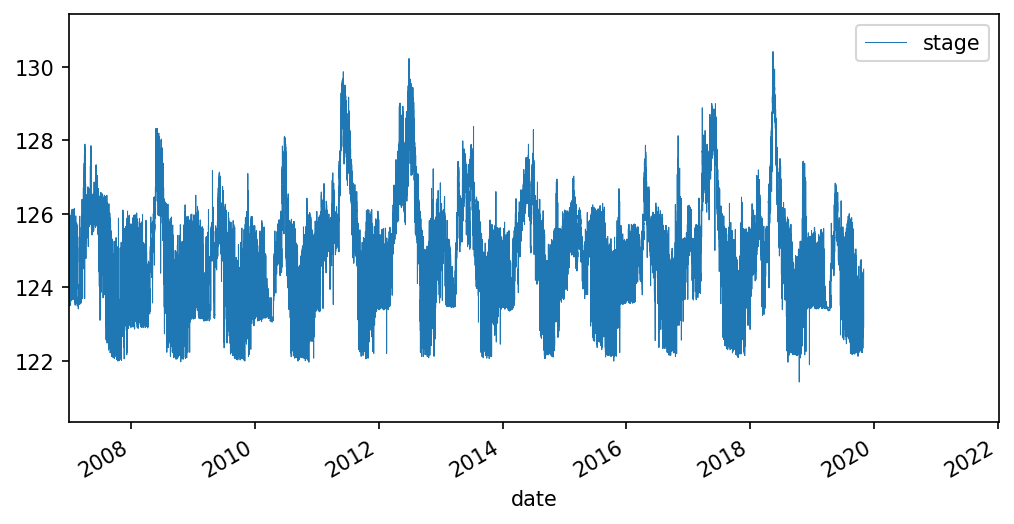

In [19]:
fig, ax = plt.subplots(1,1, figsize= (8, 4))
mass1_df.plot(y = 'stage', ax= ax, lw = 0.5)
ax.set_xlim(['01/01/2007', None])

In [36]:
mass1_df.loc['2007-01-01 00:00:00', 'stage']

123.91479346749999

(732677.0, 733041.0)

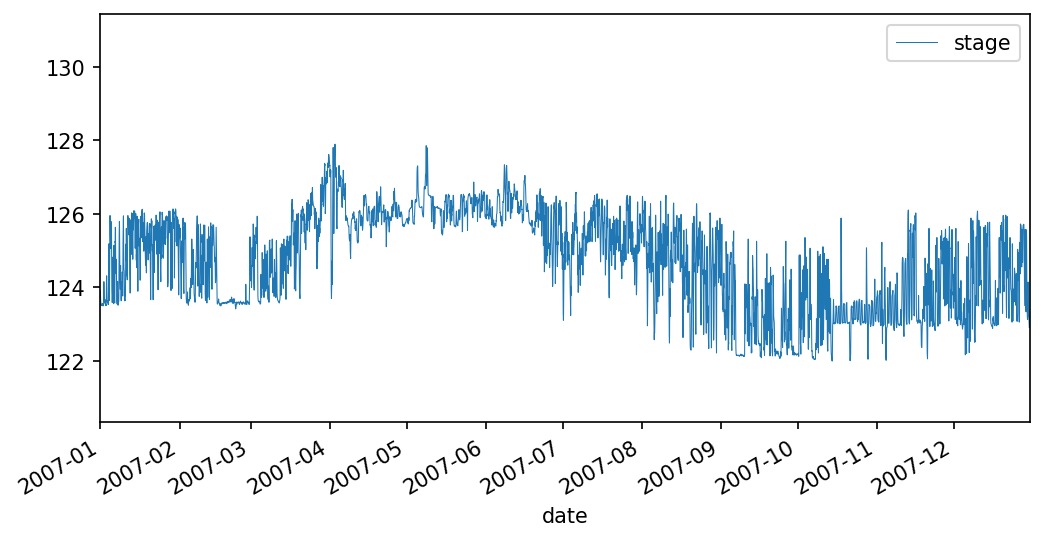

In [32]:
fig, ax = plt.subplots(1,1, figsize= (8, 4))
mass1_df.plot(y = 'stage', ax= ax, lw = 0.5)
ax.set_xlim(['01/01/2007', '12/31/2007'])

In [35]:
mass1_df.loc['01/01/2016', 'stage']

date
2016-01-01 00:00:00    124.554793
2016-01-01 01:00:00    124.564793
2016-01-01 02:00:00    124.774793
2016-01-01 03:00:00    124.904793
2016-01-01 04:00:00    125.074793
2016-01-01 05:00:00    125.194793
2016-01-01 06:00:00    125.234793
2016-01-01 07:00:00    125.254793
2016-01-01 08:00:00    125.264793
2016-01-01 09:00:00    125.224793
2016-01-01 10:00:00    124.964793
2016-01-01 11:00:00    124.444793
2016-01-01 12:00:00    123.994793
2016-01-01 13:00:00    123.784793
2016-01-01 14:00:00    123.674793
2016-01-01 15:00:00    123.644793
2016-01-01 16:00:00    123.784793
2016-01-01 17:00:00    124.424793
2016-01-01 18:00:00    124.994793
2016-01-01 19:00:00    125.154793
2016-01-01 20:00:00    125.204793
2016-01-01 21:00:00    125.134793
2016-01-01 22:00:00    124.804793
2016-01-01 23:00:00    124.214793
Name: stage, dtype: float64

In [15]:
mass1_new = mass1_df.loc['01/01/2016':'01/31/2016', 'stage'].copy()

In [16]:
idx, value = find_nearest(mass1_new.values, mass1_df.loc['2007-01-01 00:00:00', 'stage'])

In [24]:
mass1_new.iloc[idx], mass1_new.index[idx]

(123.9047934675, Timestamp('2016-01-11 19:00:00'))

(735964.0, 736329.0)

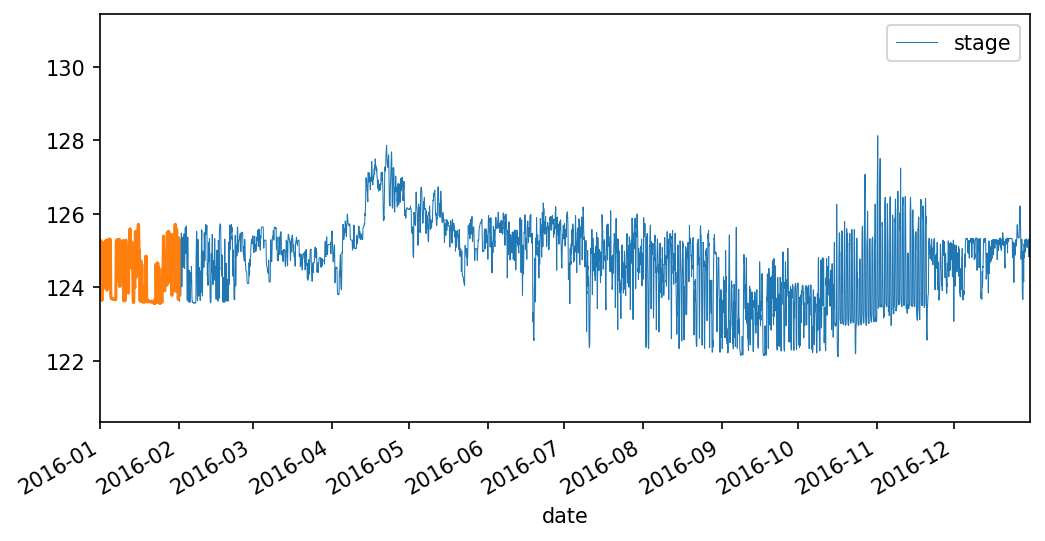

In [18]:
fig, ax = plt.subplots(1,1, figsize= (8, 4))
mass1_df.plot(y = 'stage', ax= ax, lw = 0.5)
# ax.plot(x = mass1_df.iloc[idx, 'stage'])
mass1_new.plot(y = mass1_new[idx])
ax.set_xlim(['01/01/2016', '12/31/2016'])

## import head from Reach-scale simulation

In [6]:
head = pd.read_csv(fname_head, header= None)

In [7]:
dx = dy = 100
model_ll_coord = (552050, 105050)
xlen = ylen = 60000

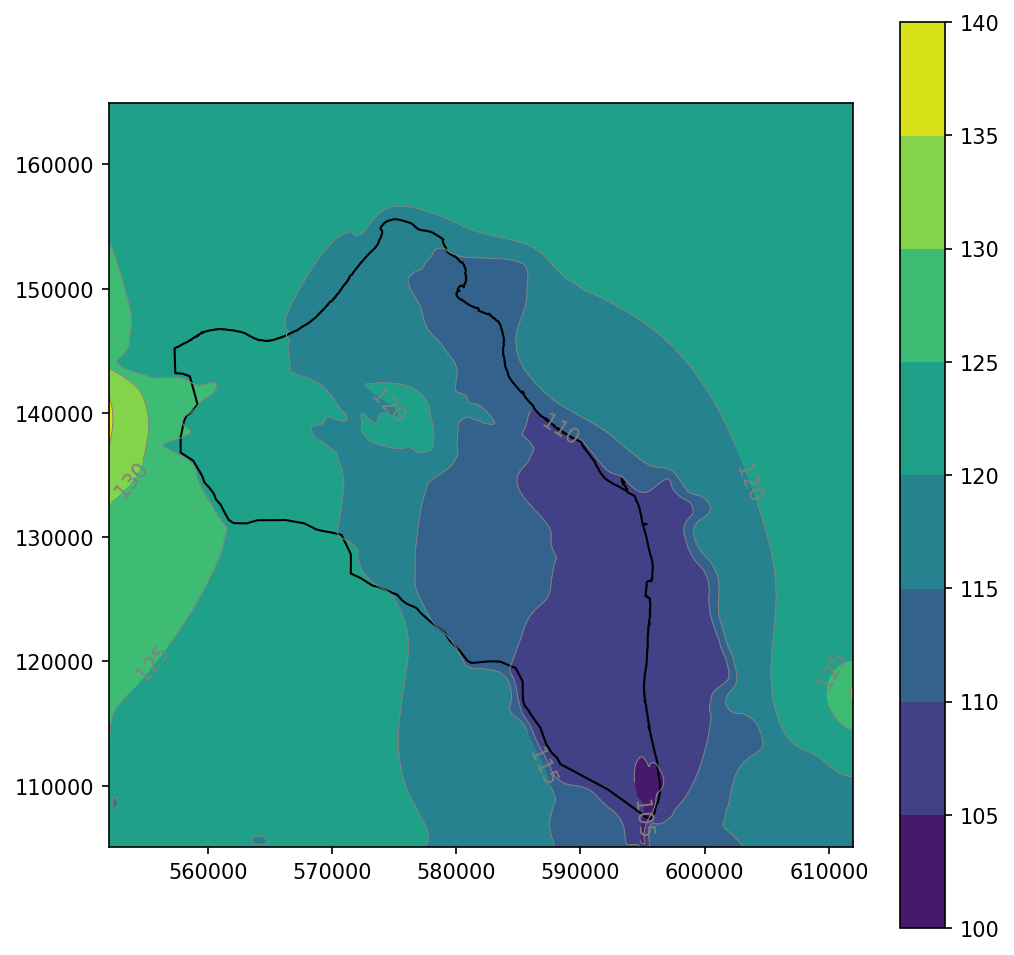

In [12]:
fig, ax = plt.subplots(1,1, figsize=(8,8))

xcoord = np.arange(model_ll_coord[0], model_ll_coord[0] + xlen -99, dx)
ycoord = np.arange(model_ll_coord[1], model_ll_coord[1] + ylen - 99, dy)

cl = ax.contour(xcoord, ycoord, head, linewidths=0.5, colors='gray')
plt.clabel(cl, inline = True, fmt = '%5.0f', fontsize = 10)

cf = ax.contourf(xcoord, ycoord, head)
plt.colorbar(cf)

boundary_shape=gpd.read_file(fname_boundary_shp)
boundary_shape.plot(facecolor = 'none', edgecolor = 'black', ax=ax, alpha=1)

## export to HDF5

**note: In PFLOTRAN initial head hdf5 file, the matrix dimension is (ny, nx); i.e. ny = ncol, nx = nrow; it starts from (x0, y0) in the upper left, while it starts from (x0, yn) in the upper left in `contourf` plot**

In [15]:
head_T = head.T

In [16]:
f = h5py.File(fname_initial_head, "w")

grp = f.create_group("Initial_Head")

dset = f.create_dataset("Initial_Head/Data", data = head_T)

In [17]:
f.visit(printname)

Initial_Head
Initial_Head/Data


**add attributes**

For strings in attributes, need to use fixed-width ASCII strings using `numpy.string_("hello")` method for maximum compatability. See [documentation](http://docs.h5py.org/en/stable/strings.html#how-to-store-text-strings)

In [18]:
grp.attrs['Cell Centered'] = 1.0
grp.attrs['Dimension'] = np.string_("XY")
grp.attrs['Discretization'] = (dx, dy)
grp.attrs['Max Buffer Size'] = 250
grp.attrs['Origin'] = model_ll_coord

In [19]:
for item in grp.attrs.keys():
    print(item + ":", grp.attrs[item])

Cell Centered: 1.0
Dimension: b'XY'
Discretization: [100 100]
Max Buffer Size: 250
Origin: [552050 105050]


In [20]:
f.close()